# 04 — Color spaces, histograms, and color segmentation

**Level:** Beginner → intermediate · 75–105 minutes  
**Prerequisites:** Read lessons 01–03: BGR, masks, arithmetic, and plotting

## What you will build and learn

- Choose useful representations of color
- Interpret intensity histograms
- Compare global and local contrast enhancement
- Build and evaluate a color-selection pipeline

## How to use this lesson

Run cells in order with **Shift+Enter**. Predict the result before running each example, then change one parameter and explain what changed. Every default example works offline after setup. Each notebook creates its own data, so previous notebooks do not need to have been run.

Try the exercises before reading the worked solutions. Use **Kernel → Restart Kernel and Run All Cells** to check that your work is reproducible. Keep your own changes in a duplicate notebook if you want to retain the reference version.


## Setup

The cell below imports the libraries and the small display/file helpers. Algorithms are written in the lesson cells. Color arrays passed to `show_images` are assumed to be BGR (OpenCV's usual order); the helper converts them to RGB for Matplotlib. Grayscale arrays are displayed directly. `rng` is a repeatable random generator, so running the notebook again reproduces its sample data.


In [1]:
from pathlib import Path
import sys

# Locate the project whether Jupyter starts in the project or notebooks folder.
start = Path.cwd().resolve()
ROOT = next((p for p in (start, *start.parents) if (p / "course_utils.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from inside the OpenCV Practical project.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import cv2
import numpy as np
import matplotlib.pyplot as plt
from course_utils import show_images, make_scene, load_image, save_image

rng = np.random.default_rng(42)
cv2.setRNGSeed(42)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10})
print(f"OpenCV {cv2.__version__} | NumPy {np.__version__}")


OpenCV 4.14.0 | NumPy 2.5.3


## Step 1 — One image, several representations

A color space is a way to describe a color numerically. BGR is convenient for storing
images, HSV separates hue from saturation and brightness, and Lab separates a lightness
coordinate from two color coordinates. `cvtColor` performs these conversions; swapping
names or channel positions is not equivalent to converting color spaces.

Grayscale discards color information, which helps when shape or brightness matters.
Different colors can become similar gray values, so grayscale cannot solve every task.


BGR: (420, 640, 3) gray: (420, 640) HSV: (420, 640, 3) Lab: (420, 640, 3)


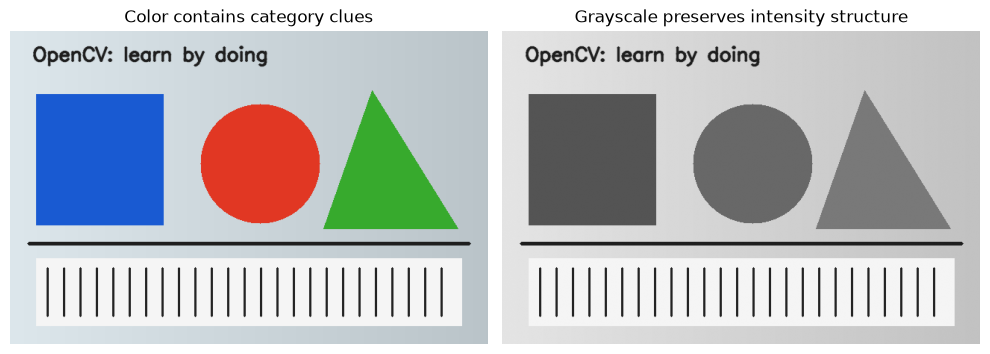

In [2]:
scene = make_scene()
gray = cv2.cvtColor(scene, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(scene, cv2.COLOR_BGR2HSV)
lab = cv2.cvtColor(scene, cv2.COLOR_BGR2LAB)
print("BGR:", scene.shape, "gray:", gray.shape, "HSV:", hsv.shape, "Lab:", lab.shape)
show_images([scene, gray], ["Color contains category clues", "Grayscale preserves intensity structure"], cols=2)


For OpenCV's ordinary **uint8 HSV** conversion, hue uses 0–179 and saturation
and value use 0–255. Hue describes a position around a color wheel. Saturation describes
colorfulness; value is the maximum BGR channel. Float conversions have different ranges,
so first check the dtype. We will use uint8 throughout this lesson.

Plot each channel separately. An HSV array passed directly to a BGR display function
will produce misleading colors because its three numbers have different meanings.


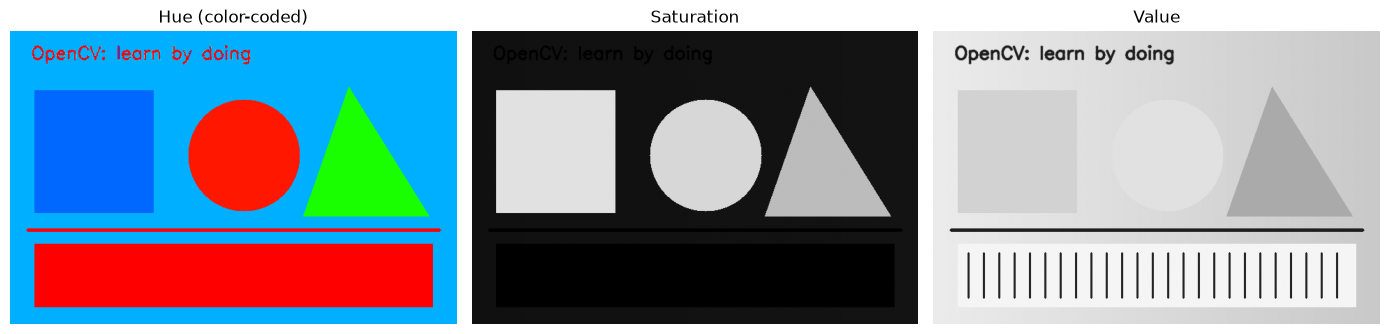

In [3]:
hue, saturation, value = cv2.split(hsv)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].imshow(hue, cmap="hsv", vmin=0, vmax=179)
axes[1].imshow(saturation, cmap="gray", vmin=0, vmax=255)
axes[2].imshow(value, cmap="gray", vmin=0, vmax=255)
for ax, title in zip(axes, ["Hue (color-coded)", "Saturation", "Value"]):
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()
assert hue.max() <= 179


### A color wheel with a boundary

Red lies near both ends of the hue scale. That wraparound matters when selecting red
pixels. Hue also becomes unreliable as a color cue when saturation is near zero:
white, gray, and black do not have a useful visible hue.


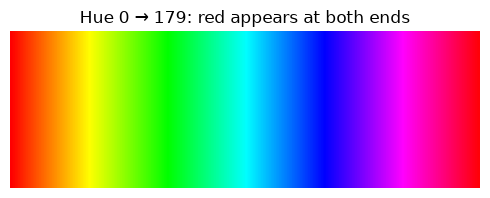

BGR at hues 0, 60, 120, 179: [[0, 0, 255], [0, 255, 0], [255, 0, 0], [8, 0, 255]]


In [4]:
hue_strip = np.zeros((60, 180, 3), dtype=np.uint8)
hue_strip[:, :, 0] = np.arange(180, dtype=np.uint8)
hue_strip[:, :, 1:] = 255
bgr_strip = cv2.cvtColor(hue_strip, cv2.COLOR_HSV2BGR)
show_images([bgr_strip], ["Hue 0 → 179: red appears at both ends"], cols=1)
print("BGR at hues 0, 60, 120, 179:", bgr_strip[0, [0, 60, 120, 179]].tolist())


## Step 2 — Select a color using ranges

`cv2.inRange(image, lower, upper)` returns a binary mask. A pixel is selected only
when **all** its channel values lie within the inclusive bounds. For red, combine a
low-hue range and a high-hue range with OR. A saturation floor excludes most gray
pixels; a value floor excludes very dark pixels.


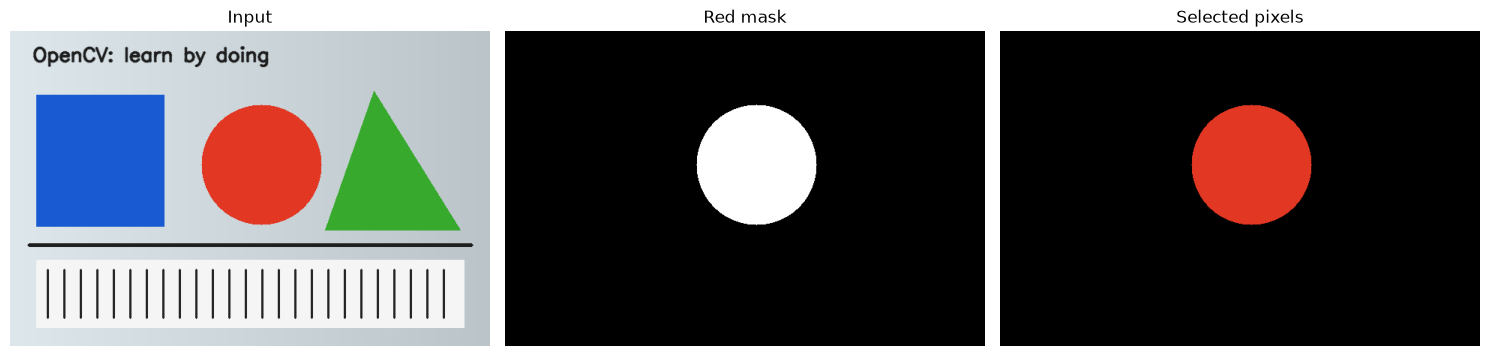

Selected area: 20081 pixels


In [5]:
red_low = cv2.inRange(hsv, (0, 90, 50), (10, 255, 255))
red_high = cv2.inRange(hsv, (170, 90, 50), (179, 255, 255))
red_mask = cv2.bitwise_or(red_low, red_high)
red_only = cv2.bitwise_and(scene, scene, mask=red_mask)
show_images([scene, red_mask, red_only], ["Input", "Red mask", "Selected pixels"])
assert red_mask.dtype == np.uint8 and red_mask.shape == scene.shape[:2]
print("Selected area:", cv2.countNonZero(red_mask), "pixels")


### Parameter experiment

Change the hue tolerance and saturation minimum below. A wider range admits more
orange/pink pixels; a lower saturation floor may admit pale backgrounds. Thresholds
that work on this scene are starting hypotheses for a new camera or lighting setup.
Inspect the mask, not only the attractive selected-color image.


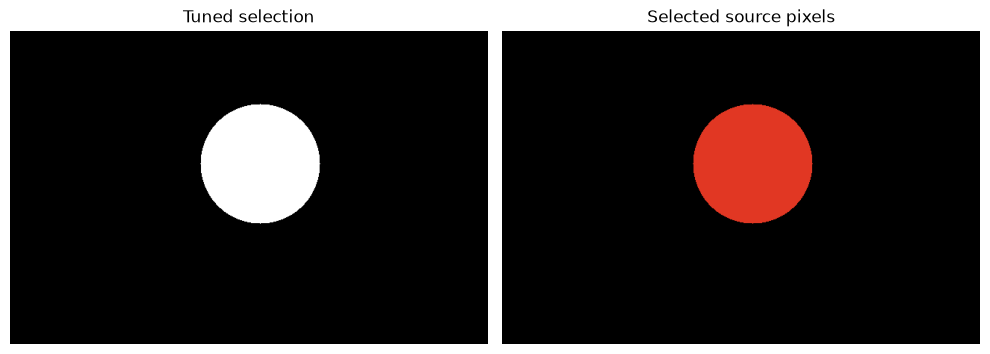

In [6]:
hue_tolerance = 10   # Try 5 and 20; valid range here is 0..30.
minimum_saturation = 90  # Try 20 and 180.
minimum_value = 50
assert 0 <= hue_tolerance <= 30
assert 0 <= minimum_saturation <= 255 and 0 <= minimum_value <= 255
tuned_mask = cv2.inRange(hsv, (0, minimum_saturation, minimum_value), (hue_tolerance, 255, 255))
# Hue wraps every 180 units: distance 1 from hue 0 includes both 1 and 179.
# At tolerance 0 there is no wrapped interval; select hue 0 only.
if hue_tolerance > 0:
    wrapped_mask = cv2.inRange(hsv, (180 - hue_tolerance, minimum_saturation, minimum_value),
                               (179, 255, 255))
    tuned_mask = cv2.bitwise_or(tuned_mask, wrapped_mask)
show_images([tuned_mask, cv2.bitwise_and(scene, scene, mask=tuned_mask)],
            ["Tuned selection", "Selected source pixels"], cols=2)


## Step 3 — Read a histogram as a count of values

A histogram counts how many pixels fall in each intensity bin. It says nothing about
where those pixels are. `calcHist([image], [channel], mask, [bins], [range_start, range_end])`
uses a list of images, a channel index, an optional selection, and a half-open range.
For uint8 intensity, 256 bins over `[0, 256]` provide one bin per possible value.


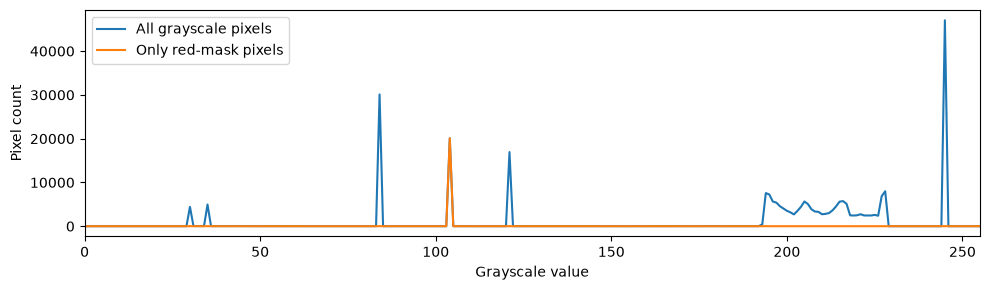

In [7]:
histogram = cv2.calcHist([gray], [0], None, [256], [0, 256]).ravel()
selected_histogram = cv2.calcHist([gray], [0], red_mask, [256], [0, 256]).ravel()
assert int(histogram.sum()) == gray.size
assert int(selected_histogram.sum()) == cv2.countNonZero(red_mask)
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(histogram, label="All grayscale pixels")
ax.plot(selected_histogram, label="Only red-mask pixels")
ax.set(xlabel="Grayscale value", ylabel="Pixel count", xlim=(0, 255))
ax.legend()
plt.tight_layout()
plt.show()


Two different arrangements can have exactly the same histogram. Flattening with
`ravel`, randomly permuting, and reshaping moves the pixels without changing their values.
This is why a histogram can help describe exposure or color distribution but cannot
uniquely identify the scene layout.


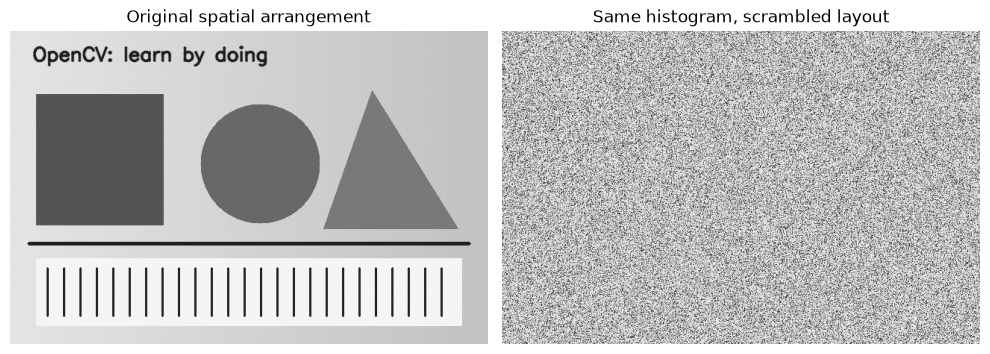

In [8]:
shuffle_rng = np.random.default_rng(42)
shuffled = shuffle_rng.permutation(gray.ravel()).reshape(gray.shape)
shuffled_hist = cv2.calcHist([shuffled], [0], None, [256], [0, 256]).ravel()
assert np.array_equal(histogram, shuffled_hist)
show_images([gray, shuffled], ["Original spatial arrangement", "Same histogram, scrambled layout"], cols=2)


## Step 4 — Improve contrast, then check what changed

Compress the grayscale values into a narrow band to simulate low contrast.
`equalizeHist` redistributes a single-channel uint8 image using its cumulative
histogram. It can reveal differences in a narrow range, but may also exaggerate noise
and change the intended appearance. More contrast is not automatically more information.


Low contrast min/max: 102 156
Equalized min/max: 0 255


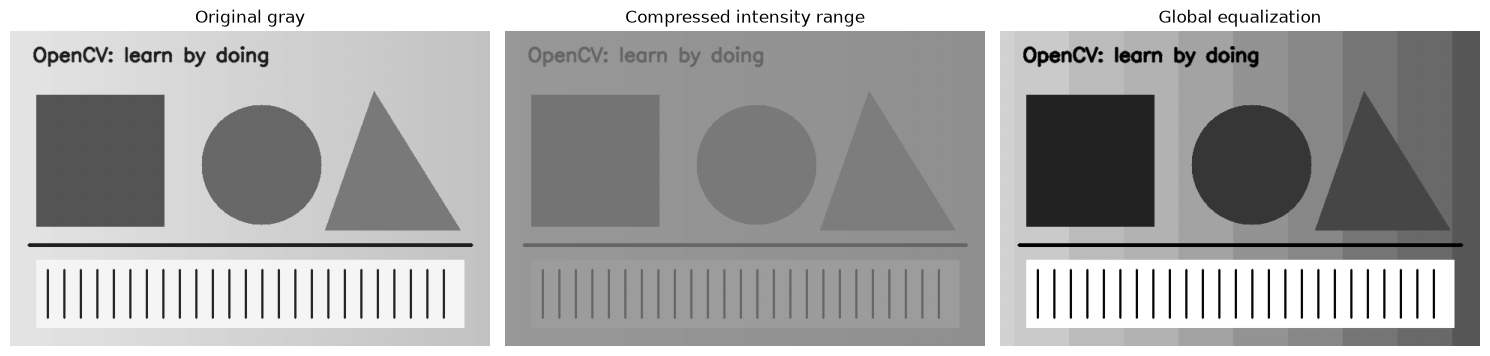

In [9]:
low_contrast = np.clip(gray.astype(np.float32) * 0.25 + 95, 0, 255).astype(np.uint8)
equalized = cv2.equalizeHist(low_contrast)
print("Low contrast min/max:", int(low_contrast.min()), int(low_contrast.max()))
print("Equalized min/max:", int(equalized.min()), int(equalized.max()))
show_images([gray, low_contrast, equalized], ["Original gray", "Compressed intensity range", "Global equalization"])


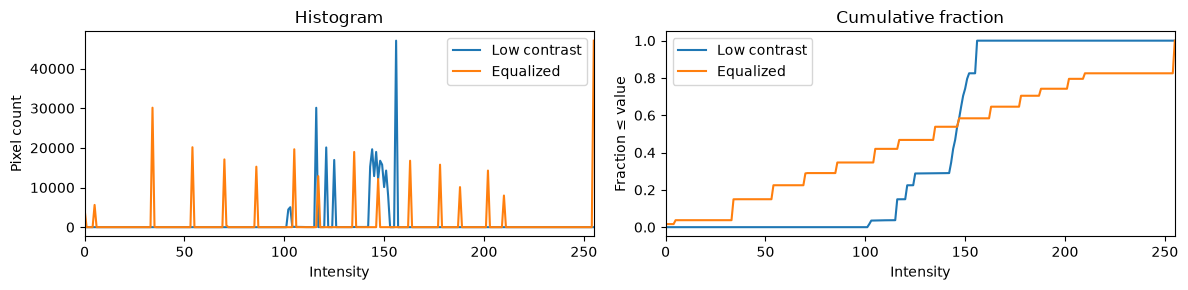

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
for image, label in [(low_contrast, "Low contrast"), (equalized, "Equalized")]:
    hist = cv2.calcHist([image], [0], None, [256], [0, 256]).ravel()
    axes[0].plot(hist, label=label)
    axes[1].plot(np.cumsum(hist) / hist.sum(), label=label)
axes[0].set(title="Histogram", xlabel="Intensity", ylabel="Pixel count", xlim=(0, 255))
axes[1].set(title="Cumulative fraction", xlabel="Intensity", ylabel="Fraction ≤ value", xlim=(0, 255))
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()


CLAHE applies contrast enhancement in local tiles while limiting histogram peaks.
`createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))` configures the operator; `apply` runs it.
The grid size is the **number of tiles**, not a kernel measured in pixels. The clip
limit controls contrast amplification. Compare details in bright and dark regions.


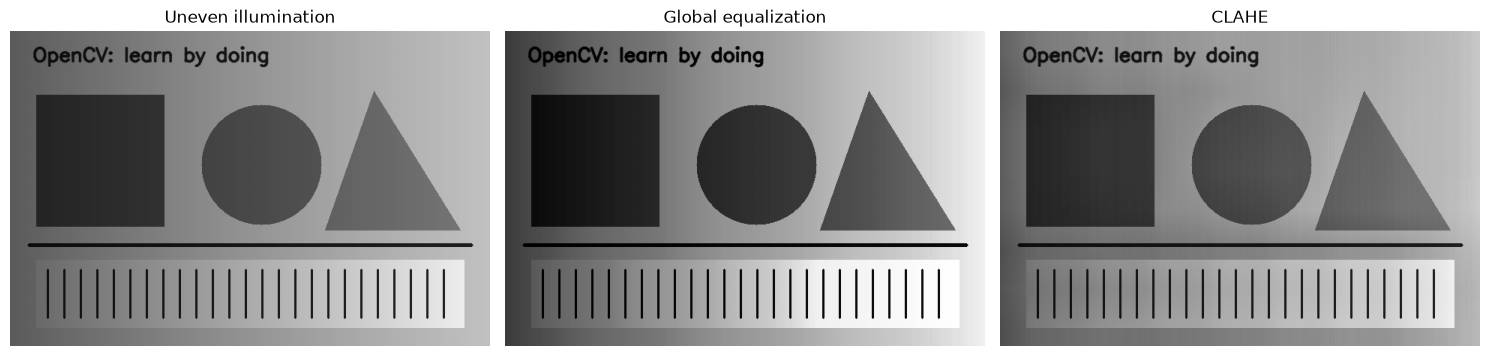

In [11]:
illumination = np.linspace(0.40, 1.0, gray.shape[1], dtype=np.float32)[None, :]
uneven_gray = np.clip(gray.astype(np.float32) * illumination, 0, 255).astype(np.uint8)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
local_equalized = clahe.apply(uneven_gray)
show_images([uneven_gray, cv2.equalizeHist(uneven_gray), local_equalized],
            ["Uneven illumination", "Global equalization", "CLAHE"])


## Step 5 — Adjust lightness in a color image

Equalizing B, G, and R separately can change their relative proportions and shift colors.
An alternative is to convert to Lab, adjust its lightness channel, and convert back.
For uint8 Lab, OpenCV stores an encoded lightness in 0–255 and offsets its color
coordinates. Treat these stored values as encoded coordinates, not direct physical units.
Conversion, clipping, and gamut limits mean this is not perfect color preservation.


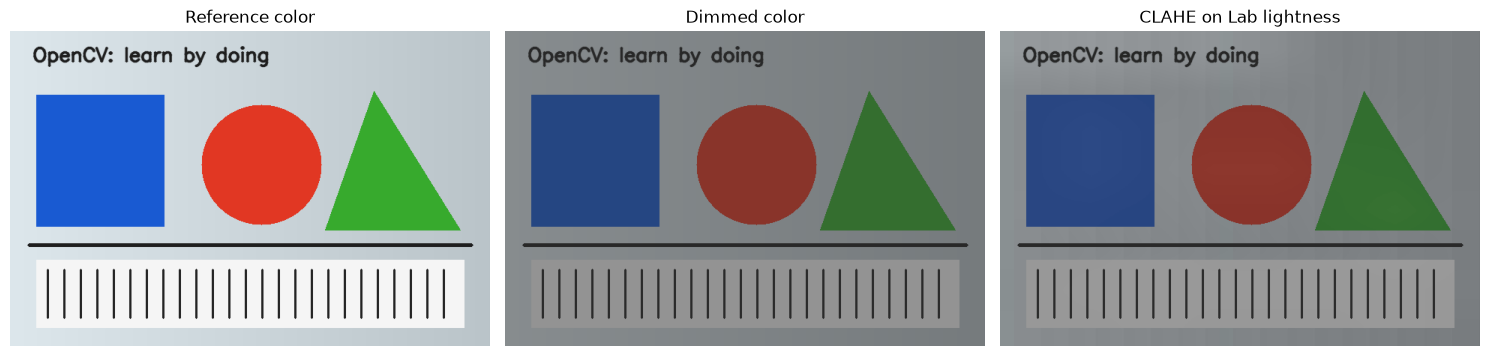

In [12]:
dim_color = np.clip(scene.astype(np.float32) * 0.50 + 25, 0, 255).astype(np.uint8)
dim_lab = cv2.cvtColor(dim_color, cv2.COLOR_BGR2LAB)
lightness, a_channel, b_channel = cv2.split(dim_lab)
enhanced_lightness = clahe.apply(lightness)
enhanced_lab = cv2.merge([enhanced_lightness, a_channel, b_channel])
enhanced_color = cv2.cvtColor(enhanced_lab, cv2.COLOR_LAB2BGR)
show_images([scene, dim_color, enhanced_color], ["Reference color", "Dimmed color", "CLAHE on Lab lightness"])
assert enhanced_color.shape == scene.shape and enhanced_color.dtype == np.uint8


### Contrast experiment

Try clip limits 1.0, 2.0, and 6.0. Record which setting improves small details without
making smooth regions distracting. A photograph with sensor noise is a harder test
than a clean generated image; later, compare both rather than trusting one example.


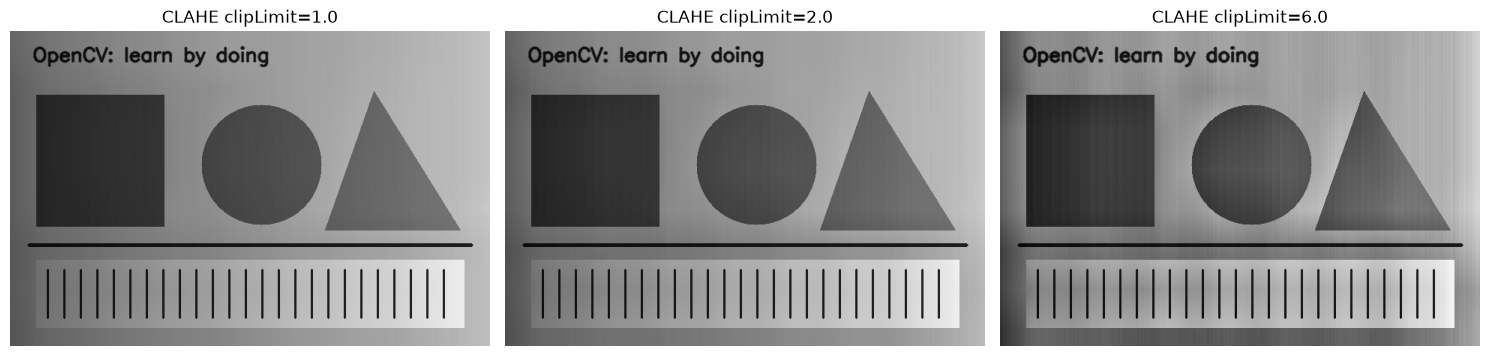

In [13]:
clip_limits = [1.0, 2.0, 6.0]
contrast_variants = [cv2.createCLAHE(clipLimit=limit, tileGridSize=(8, 8)).apply(uneven_gray)
                     for limit in clip_limits]
show_images(contrast_variants, [f"CLAHE clipLimit={limit}" for limit in clip_limits])


## Step 6 — Mini-project: measure a red marker under changing brightness

Generate a known target and a green distractor. The target's ground-truth mask tells
us which pixels should be selected. Measure intersection over union (IoU): selected
overlap divided by all pixels selected by either mask. A perfect mask scores 1.
Brightness scaling is only one controlled stress test; it does not simulate every real
lighting change, reflection, shadow, or camera white-balance adjustment.


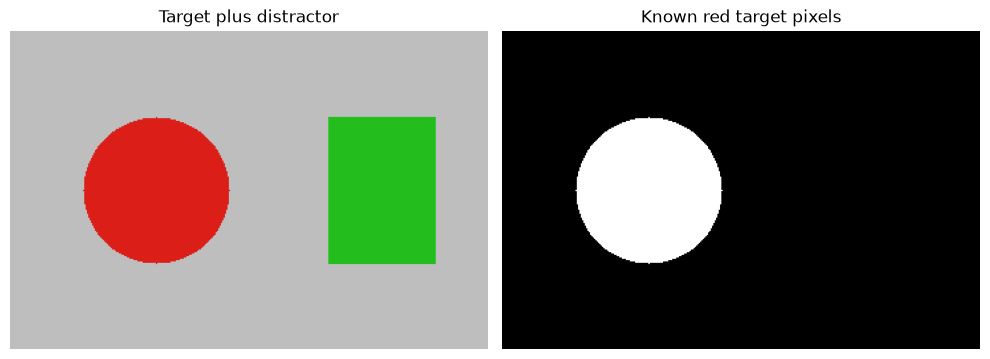

In [14]:
target = np.full((240, 360, 3), 190, dtype=np.uint8)
truth = np.zeros(target.shape[:2], dtype=np.uint8)
cv2.circle(target, (110, 120), 55, (25, 30, 220), -1)
cv2.circle(truth, (110, 120), 55, 255, -1)
cv2.rectangle(target, (240, 65), (320, 175), (30, 190, 35), -1)

def select_red(image, saturation_min=90, value_min=50):
    converted = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    first = cv2.inRange(converted, (0, saturation_min, value_min), (10, 255, 255))
    second = cv2.inRange(converted, (170, saturation_min, value_min), (179, 255, 255))
    return cv2.bitwise_or(first, second)

def mask_iou(predicted, expected):
    p, e = predicted > 0, expected > 0
    union_size = np.count_nonzero(p | e)
    return float(np.count_nonzero(p & e) / union_size) if union_size else 1.0

assert mask_iou(truth, truth) == 1.0
show_images([target, truth], ["Target plus distractor", "Known red target pixels"], cols=2)


Brightness 1.00: selected  9477 pixels, IoU=1.000
Brightness 0.55: selected  9477 pixels, IoU=1.000
Brightness 0.15: selected     0 pixels, IoU=0.000


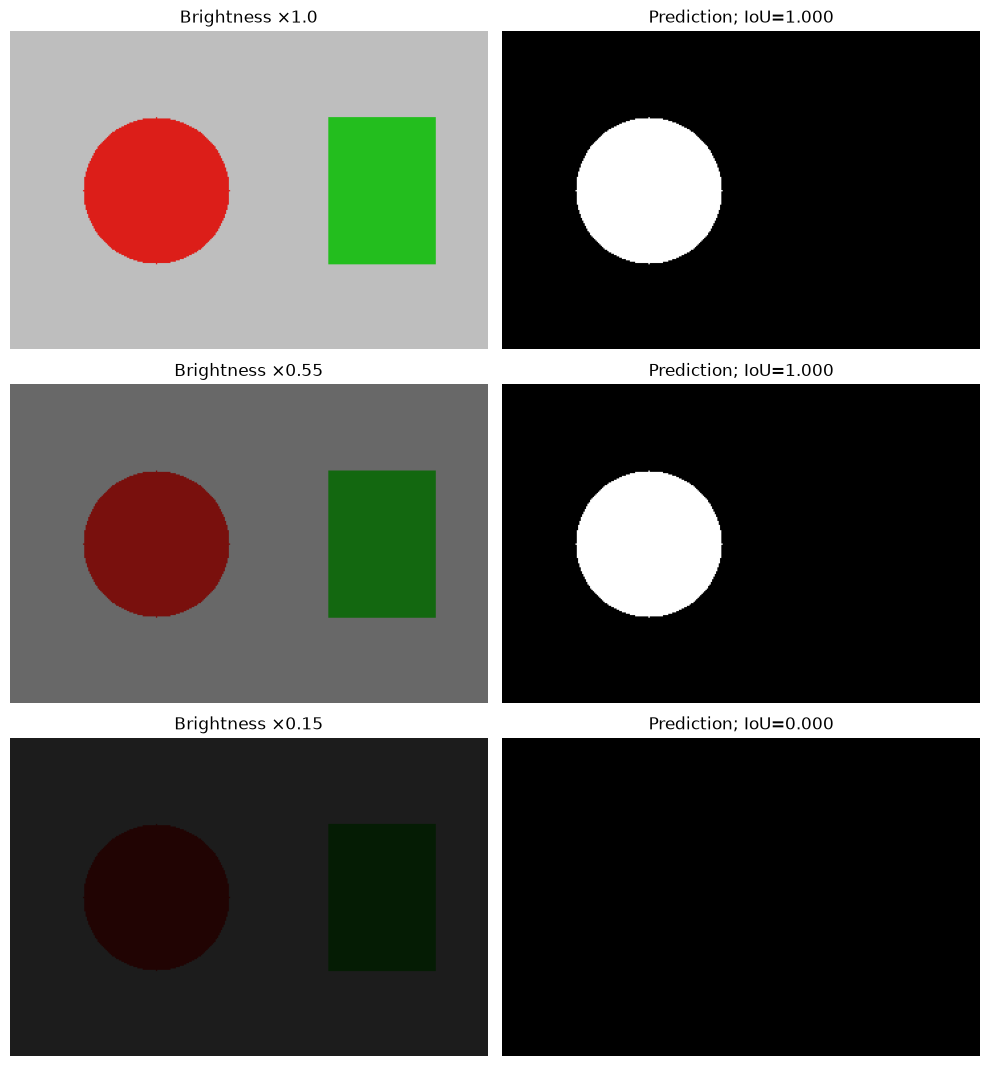

In [15]:
brightness_factors = [1.0, 0.55, 0.15]
project_images, project_titles = [], []
for factor in brightness_factors:
    dimmed = np.clip(target.astype(np.float32) * factor, 0, 255).astype(np.uint8)
    prediction = select_red(dimmed)
    score = mask_iou(prediction, truth)
    print(f"Brightness {factor:.2f}: selected {cv2.countNonZero(prediction):5} pixels, IoU={score:.3f}")
    project_images.extend([dimmed, prediction])
    project_titles.extend([f"Brightness ×{factor}", f"Prediction; IoU={score:.3f}"])
show_images(project_images, project_titles, cols=2)


**Expected observation:** the very dark marker is rejected by the fixed value
floor, even if its hue still looks red. Lowering the floor can recover it, but may admit
dark noise in real images. Evaluation makes this tradeoff explicit.

### Exercises — attempt first

1. Recover the darkest synthetic marker by changing only `value_min`. Report IoU.
2. Select the green distractor with a suitable HSV range and report its area.
3. Plot the B, G, and R histograms separately. Explain why a channel histogram alone
   cannot prove that a red object occupies a particular location.


In [16]:
# Your practice area. Example: inspect HSV values at the marker center.
print("Dark marker HSV:", cv2.cvtColor(dimmed, cv2.COLOR_BGR2HSV)[120, 110])


Dark marker HSV: [  1 232  33]


### Worked solutions

The selected value floor below is justified by inspecting this known synthetic target.
The green range is another dataset-specific choice. Inspecting representative pixels
is a better starting point than memorizing thresholds as universal constants.


Recovered red IoU: 1.0
Green area: 8991


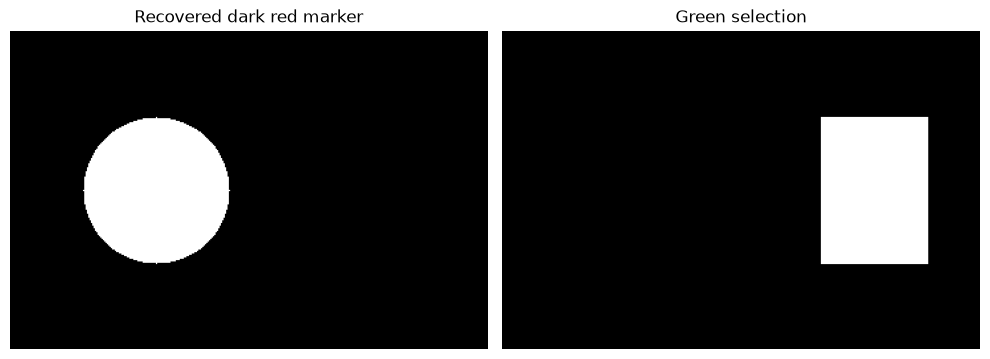

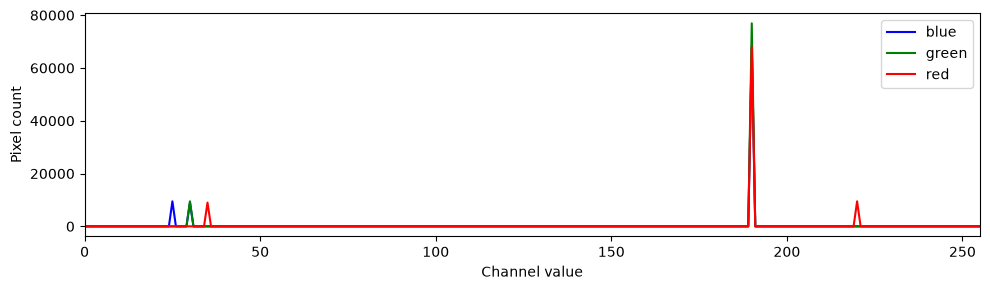

In [17]:
dark_target = (target.astype(np.float32) * 0.15).astype(np.uint8)
recovered = select_red(dark_target, value_min=20)
print("Recovered red IoU:", mask_iou(recovered, truth))
assert mask_iou(recovered, truth) > 0.99
green_mask = cv2.inRange(cv2.cvtColor(target, cv2.COLOR_BGR2HSV), (40, 90, 50), (85, 255, 255))
print("Green area:", cv2.countNonZero(green_mask))
show_images([recovered, green_mask], ["Recovered dark red marker", "Green selection"], cols=2)

fig, ax = plt.subplots(figsize=(10, 3))
for index, color_name in enumerate(["blue", "green", "red"]):
    hist = cv2.calcHist([target], [index], None, [256], [0, 256]).ravel()
    ax.plot(hist, color=color_name, label=color_name)
ax.set(xlabel="Channel value", ylabel="Pixel count", xlim=(0, 255))
ax.legend()
plt.tight_layout()
plt.show()


### Reflection

- Why does red need two hue intervals? Why does gray need a saturation check?
- Can a color histogram identify an object's position? Use the shuffle experiment as evidence.
- Which details did global equalization help, and which did CLAHE help?
- What additional photographs would test whether your color selector generalizes?

Official references: [Color spaces and inRange](https://docs.opencv.org/4.x/df/d9d/tutorial_py_colorspaces.html),
[Histograms](https://docs.opencv.org/4.x/d1/db7/tutorial_py_histogram_begins.html),
[Histogram equalization and CLAHE](https://docs.opencv.org/4.x/d5/daf/tutorial_py_histogram_equalization.html).
